# SAR Ship Detection on SSDD: YOLOv4 / YOLOv8 / YOLO11 + S-Net (TensorFlow) refiner

Pipeline: **detector (coarse boxes) -> ROI crop -> S-Net (TensorFlow/Keras) -> refined boxes**.
The same S-Net refiner is applied to YOLOv4 first, then YOLOv8, then YOLO11, so the S-Net gain can be compared.

Outputs: metrics table, S-Net delta table, PR curves, precision-vs-confidence / precision-vs-IoU graphs,
confusion matrices, and per-ship latitude / longitude with distance to the nearest dock.

**Before running:** upload `archive.zip` (Roboflow SSDD YOLO export) to `/content`, use a GPU runtime.
Switches are in the config cell (section 1).

## 0. Setup

In [ ]:
import os, subprocess
subprocess.run("rm -rf /content/sar_data && unzip -qo /content/archive.zip -d /content/sar_data", shell=True, check=True)
subprocess.run("pip install -q ultralytics", shell=True, check=True)   # TensorFlow, matplotlib, pandas are preinstalled on Colab
print(os.listdir("/content/sar_data"))

['SSDD_coco']


## 1. Config

In [ ]:
import os, glob, math, random, json, re, shutil, subprocess, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

SRC  = "/content/sar_data"     # Roboflow export (polygon labels)
BASE = "/content/sar_box"      # converted copy with plain box labels, used by ALL detectors

IMGSZ        = 416             # training / inference size for all detectors (multiple of 32)
EPOCHS       = 30              # YOLOv8 / YOLO11 epochs
RUN_YOLOV4   = True            # needs a Darknet build (section 6). Set False to skip if the build fails
YOLOV4_VARIANT = "full"        # "full" (yolov4) or "tiny" (yolov4-tiny, much faster)
DARKNET_ITERS  = 2000          # YOLOv4 training iterations (batch 64). ~2 h on a T4 for "full"
SNET_EPOCHS  = 30

EVAL_CONF = 0.01               # lowest confidence kept for mAP / PR curves
OP_CONF   = 0.25               # operating point for P / R / F1 / confusion matrix
IOU_MATCH = 0.50               # IoU for TP at the operating point

random.seed(0); np.random.seed(0)
SPLITS = ["train", "valid", "test"]

## 2. Label helpers and box-label dataset

In [ ]:
IMG_EXT = (".jpg", ".jpeg", ".png")

def list_images(d): return sorted(f for f in os.listdir(d) if f.lower().endswith(IMG_EXT))

def read_yolo_labels(path):
    """YOLO txt (5-value rows or polygon rows) -> list of [cx, cy, w, h] normalised."""
    boxes = []
    if not os.path.exists(path): return boxes
    for line in open(path):
        p = line.split()
        if len(p) < 5: continue
        v = [float(x) for x in p[1:]]
        if len(v) == 4: cx, cy, w, h = v
        else:
            xs, ys = v[0::2], v[1::2]
            x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
            cx, cy, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
        if w > 0 and h > 0: boxes.append([cx, cy, w, h])
    return boxes

def read_json_labels(path):
    """Parses SSDD JSON label file if available, returning list of [cx, cy, w, h] normalized."""
    boxes = []
    if not os.path.exists(path): return boxes
    try:
        import json
        data = json.load(open(path))
        # SSDD JSON schema often contains shapes or bboxes under 'shapes' or 'annotations'
        # Let's check for shapes with points
        for shape in data.get("shapes", []):
            pts = shape.get("points", [])
            if len(pts) >= 2:
                xs = [p[0] for p in pts]
                ys = [p[1] for p in pts]
                x0, y0, x1, y1 = min(xs), min(ys), max(xs), max(ys)
                image_w = data.get("imageWidth", 1.0)
                image_h = data.get("imageHeight", 1.0)
                cx = ((x0 + x1) / 2.0) / image_w
                cy = ((y0 + y1) / 2.0) / image_h
                w = (x1 - x0) / image_w
                h = (y1 - y0) / image_h
                if w > 0 and h > 0: boxes.append([cx, cy, w, h])
    except Exception as e:
        pass
    return boxes

def cxcywh_to_xyxy(b, W, H):
    cx, cy, w, h = b
    return [(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H]

def jitter_box(b, jitter, rng):
    x0, y0, x1, y1 = b; bw, bh = x1 - x0, y1 - y0
    cx = (x0 + x1) / 2 + rng.uniform(-jitter, jitter) * bw
    cy = (y0 + y1) / 2 + rng.uniform(-jitter, jitter) * bh
    bw *= 1 + rng.uniform(-jitter, jitter); bh *= 1 + rng.uniform(-jitter, jitter)
    return [cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2]

def padded_crop(b, W, H, pad=0.15):
    x0, y0, x1, y1 = b; px, py = (x1 - x0) * pad, (y1 - y0) * pad
    c = (max(0, math.floor(x0 - px)), max(0, math.floor(y0 - py)),
         min(W, math.ceil(x1 + px)), min(H, math.ceil(y1 + py)))
    return (0, 0, W, H) if (c[2] - c[0] < 4 or c[3] - c[1] < 4) else c

def box_to_crop_norm(b, crop):
    cw, ch = crop[2] - crop[0], crop[3] - crop[1]
    x0, y0, x1, y1 = b
    t = [((x0 + x1) / 2 - crop[0]) / cw, ((y0 + y1) / 2 - crop[1]) / ch, (x1 - x0) / cw, (y1 - y0) / ch]
    return [min(max(v, 0.0), 1.0) for v in t]

def crop_norm_to_box(n, crop):
    cw, ch = crop[2] - crop[0], crop[3] - crop[1]; cx, cy, w, h = n
    return [crop[0] + (cx - w / 2) * cw, crop[1] + (cy - h / 2) * ch,
            crop[0] + (cx + w / 2) * cw, crop[1] + (cy + h / 2) * ch]

# Adjust SRC path dynamically
actual_src = SRC
if not os.path.exists(f"{actual_src}/train"):
    subdirs = [d for d in os.listdir(actual_src) if os.path.isdir(os.path.join(actual_src, d))]
    if subdirs:
        actual_src = os.path.join(actual_src, subdirs[0])

# Get all images in actual_src
all_images = list_images(actual_src)
print(f"Found {len(all_images)} flat images in {actual_src}. Partitioning into splits...")

# Seed for deterministic splitting
import random as rd
rd.seed(42)
rd.shuffle(all_images)

n_total = len(all_images)
n_tr = int(n_total * 0.8)
n_va = int(n_total * 0.1)

split_maps = {
    "train": all_images[:n_tr],
    "valid": all_images[n_tr:n_tr+n_va],
    "test": all_images[n_tr+n_va:]
}

shutil.rmtree(BASE, ignore_errors=True)
for s in SPLITS:
    os.makedirs(f"{BASE}/{s}/images"); os.makedirs(f"{BASE}/{s}/labels")
    for name in split_maps[s]:
        # Copy image
        shutil.copy(f"{actual_src}/{name}", f"{BASE}/{s}/images/{name}")

        # Read label: try .txt first, then fallback to .json with same base name
        base_name = os.path.splitext(name)[0]
        txt_path = f"{actual_src}/{base_name}.txt"
        json_path = f"{actual_src}/{base_name}.json"

        if os.path.exists(txt_path):
            bx = read_yolo_labels(txt_path)
        elif os.path.exists(json_path):
            bx = read_json_labels(json_path)
        else:
            bx = []

        with open(f"{BASE}/{s}/labels/{base_name}.txt", "w") as f:
            for b in bx: f.write("0 " + " ".join(f"{v:.6f}" for v in b) + "\n")

with open(f"{BASE}/data.yaml", "w") as f:
    f.write(f"path: {BASE}\ntrain: train/images\nval: valid/images\ntest: test/images\nnc: 1\nnames: ['ship']\n")

IMGS = {s: list_images(f"{BASE}/{s}/images") for s in SPLITS}
_IM = {}
def load_img(split, name):
    k = (split, name)
    if k not in _IM: _IM[k] = Image.open(f"{BASE}/{split}/images/{name}").convert("RGB")
    return _IM[k]

def gt_boxes(split):
    out = {}
    for name in IMGS[split]:
        W, H = load_img(split, name).size
        b = read_yolo_labels(f"{BASE}/{split}/labels/{os.path.splitext(name)[0]}.txt")
        out[name] = np.array([cxcywh_to_xyxy(x, W, H) for x in b], dtype=np.float32).reshape(-1, 4)
    return out

GT = {s: gt_boxes(s) for s in ["valid", "test"]}
for s in SPLITS: print(f"{s:5s}: {len(IMGS[s])} images", "| ships:", sum(len(v) for v in GT[s].values()) if s in GT else "-")

Found 1160 flat images in /content/sar_data/SSDD_coco. Partitioning into splits...
train: 928 images | ships: -
valid: 116 images | ships: 227
test : 116 images | ships: 264


In [ ]:
import os
def print_tree(startpath, max_depth=3):
    for root, dirs, files in os.walk(startpath):
        depth = root.replace(startpath, '').count(os.sep)
        if depth < max_depth:
            indent = ' ' * 4 * (depth)
            print(f'{indent}{os.path.basename(root)}/')
            subindent = ' ' * 4 * (depth + 1)
            for f in files[:3]:
                print(f'{subindent}{f}')
            if len(files) > 3:
                print(f'{subindent}... ({len(files)} files)')

if os.path.exists('/content/sar_data'):
    print_tree('/content/sar_data')

sar_data/
    SSDD_coco/
        001051.json
        000746.jpg
        000572.json
        ... (2320 files)


## 3. Evaluator (one implementation for every model)
Same code scores every detector, so numbers are comparable. It gives AP50, AP50-95 (COCO 101-point), precision/recall/F1
at `OP_CONF`, precision-vs-confidence, precision-vs-IoU, PR curve and a confusion matrix.

In [ ]:
def iou_matrix(a, b):
    a = np.asarray(a, float).reshape(-1, 4); b = np.asarray(b, float).reshape(-1, 4)
    ix0 = np.maximum(a[:, None, 0], b[None, :, 0]); iy0 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix1 = np.minimum(a[:, None, 2], b[None, :, 2]); iy1 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix1 - ix0, 0, None) * np.clip(iy1 - iy0, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def match_detections(preds, gts, iou_thr, min_conf=0.0):
    """Greedy matching by descending score. Returns (scores, is_tp, n_gt) over the whole split."""
    S, T, n_gt = [], [], 0
    for name, g in gts.items():
        n_gt += len(g)
        b, s = preds.get(name, (np.zeros((0, 4)), np.zeros(0)))
        keep = s >= min_conf; b, s = b[keep], s[keep]
        o = np.argsort(-s); b, s = b[o], s[o]
        used = np.zeros(len(g), bool); hit = np.zeros(len(b), bool)
        if len(b) and len(g):
            ious = iou_matrix(b, g)
            for i in range(len(b)):
                cand = np.where(~used)[0]
                if len(cand) == 0: break
                j = cand[np.argmax(ious[i, cand])]
                if ious[i, j] >= iou_thr: used[j] = True; hit[i] = True
        S.append(s); T.append(hit)
    return (np.concatenate(S) if S else np.zeros(0)), (np.concatenate(T) if T else np.zeros(0, bool)), n_gt

def pr_curve(scores, tp, n_gt):
    o = np.argsort(-scores); tp = tp[o]
    ctp = np.cumsum(tp); cfp = np.cumsum(~tp)
    return ctp / max(n_gt, 1), ctp / np.maximum(ctp + cfp, 1e-9), scores[o]

def average_precision(rec, prec):
    # COCO-style 101-point AP: precision envelope, 0 beyond the max reached recall
    if len(rec) == 0: return 0.0
    env = np.flip(np.maximum.accumulate(np.flip(prec)))
    idx = np.searchsorted(rec, np.linspace(0, 1, 101), side="left")
    return float(np.where(idx < len(rec), env[np.minimum(idx, len(rec) - 1)], 0.0).mean())

IOU_GRID = np.round(np.arange(0.5, 0.96, 0.05), 2)
CONF_GRID = np.linspace(0.05, 0.95, 19)

def evaluate(preds, gts):
    aps = []
    for t in IOU_GRID:
        s, tp, n = match_detections(preds, gts, t)
        r, p, _ = pr_curve(s, tp, n); aps.append(average_precision(r, p))
        if t == 0.5: pr50 = (r, p); s50, tp50, n50 = s, tp, n
    s, tp, n = match_detections(preds, gts, IOU_MATCH, min_conf=OP_CONF)
    TP = int(tp.sum()); FP = int(len(tp) - TP); FN = int(n - TP)
    P = TP / max(TP + FP, 1); R = TP / max(n, 1); F1 = 2 * P * R / max(P + R, 1e-9)
    p_conf = [(tp50[s50 >= c].sum() / max((s50 >= c).sum(), 1)) for c in CONF_GRID]
    p_iou = []
    for t in IOU_GRID:
        s_, tp_, _ = match_detections(preds, gts, t, min_conf=OP_CONF)
        p_iou.append(tp_.sum() / max(len(tp_), 1))
    return dict(P=P, R=R, F1=F1, mAP50=aps[0], **{"mAP50-95": float(np.mean(aps))}, TP=TP, FP=FP, FN=FN,
                pr=pr50, p_conf=np.array(p_conf), p_iou=np.array(p_iou),
                cm=np.array([[TP, FP], [FN, 0]]))   # rows: predicted ship / background, cols: true ship / background

## 4. S-Net refiner (TensorFlow / Keras)
Trained once on jittered ground-truth ROI crops (15 % padding, up to +/-10 % jitter, mimicking detector error) and then
reused for YOLOv4, YOLOv8 and YOLO11.

TF 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
ROI crops  train: 2096 | valid: 227
Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 41s - 1s/step - iou_metric: 0.7304 - loss: 0.0116 - val_iou_metric: 0.8149 - val_loss: 0.0032
Epoch 2/30
33/33 - 8s - 231ms/step - iou_metric: 0.8314 - loss: 0.0027 - val_iou_metric: 0.8356 - val_loss: 0.0027
Epoch 3/30
33/33 - 11s - 318ms/step - iou_metric: 0.8505 - loss: 0.0023 - val_iou_metric: 0.8435 - val_loss: 0.0025
Epoch 4/30
33/33 - 7s - 223ms/step - iou_metric: 0.8539 - loss: 0.0023 - val_iou_metric: 0.8419 - val_loss: 0.0025
Epoch 5/30
33/33 - 8s - 240ms/step - iou_metric: 0.8619 - loss: 0.0020 - val_iou_metric: 0.8512 - val_loss: 0.0023
Epoch 6/30
33/33 - 7s - 220ms/step - iou_metric: 0.8645 - loss: 0.0019 - val_iou_metric: 0.8526 - val_loss: 0.0023
Epoch 7/30
33/33 - 8s - 235ms/step - iou_metric: 0.8684 - loss: 0.0019 - val_iou_metric: 0.8547 - val_loss: 0.0024
Epoch 8/30
33/33 - 7s - 222ms/step - iou_metric: 0.8679 - loss: 0.0019 - val_iou_metric: 0.8578 - val_loss: 0.0024
Epoch 9/30
33/33 - 7s - 226ms/step - iou_metric: 0.8684 - loss: 0.0019 - val_iou_metric: 0.8

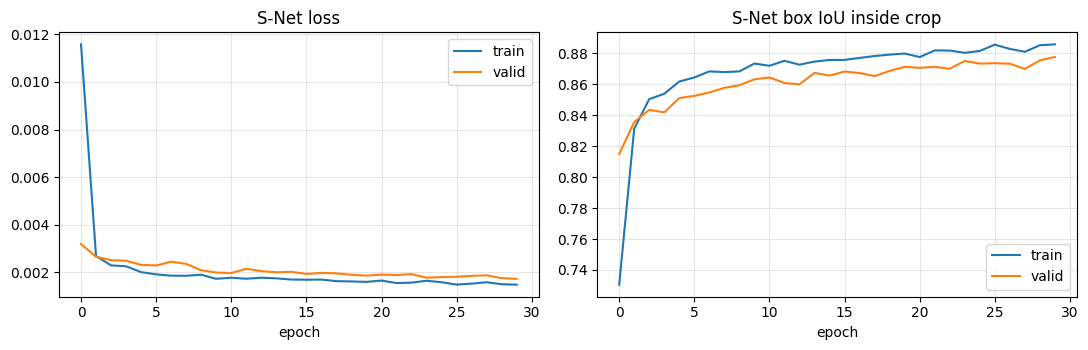

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(0)
print("TF", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

CROP = 256

def build_snet():
    inp = keras.Input((CROP, CROP, 3))
    x = inp
    for f in (16, 32, 64):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    for u in (128, 64, 32): x = layers.Dense(u, activation="relu")(x)
    out = layers.Dense(4, activation="sigmoid")(x)          # cx, cy, w, h inside the crop (0-1)
    return keras.Model(inp, out, name="S-Net")

def snet_loss(y, p):
    return tf.reduce_mean(tf.square(y - p)) + tf.reduce_mean(keras.losses.huber(y, p))

def iou_metric(y, p):
    def xyxy(t): return t[:, 0] - t[:, 2] / 2, t[:, 1] - t[:, 3] / 2, t[:, 0] + t[:, 2] / 2, t[:, 1] + t[:, 3] / 2
    ax0, ay0, ax1, ay1 = xyxy(y); bx0, by0, bx1, by1 = xyxy(p)
    iw = tf.maximum(0.0, tf.minimum(ax1, bx1) - tf.maximum(ax0, bx0))
    ih = tf.maximum(0.0, tf.minimum(ay1, by1) - tf.maximum(ay0, by0))
    inter = iw * ih
    return tf.reduce_mean(inter / (y[:, 2] * y[:, 3] + p[:, 2] * p[:, 3] - inter + 1e-9))

def roi_dataset(split, train, pad=0.15, jitter=0.10, batch=64):
    items = []
    for name in IMGS[split]:
        im = load_img(split, name); W, H = im.size
        for g in GT_ALL[split][name]: items.append((im, g.tolist(), W, H))
    def gen():
        idx = list(range(len(items)))
        rng = random.Random()
        if train: rng.shuffle(idx)
        for i in idx:
            im, g, W, H = items[i]
            r = rng if train else random.Random(i)
            crop = padded_crop(jitter_box(g, jitter, r), W, H, pad)
            x = np.asarray(im.crop(crop).resize((CROP, CROP), Image.BILINEAR), np.float32) / 255.0
            yield x, np.array(box_to_crop_norm(g, crop), np.float32)
    sig = (tf.TensorSpec((CROP, CROP, 3), tf.float32), tf.TensorSpec((4,), tf.float32))
    return tf.data.Dataset.from_generator(gen, output_signature=sig).batch(batch).prefetch(2), len(items)

GT_ALL = {"train": gt_boxes("train"), "valid": GT["valid"], "test": GT["test"]}
ds_tr, n_tr = roi_dataset("train", True); ds_va, n_va = roi_dataset("valid", False)
print("ROI crops  train:", n_tr, "| valid:", n_va)

snet = build_snet()
snet.compile(optimizer=keras.optimizers.Adam(1e-3), loss=snet_loss, metrics=[iou_metric])
hist = snet.fit(ds_tr, validation_data=ds_va, epochs=SNET_EPOCHS, verbose=2)
snet.save("SNet_ROI_Refiner.keras")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="valid"); ax[0].set_title("S-Net loss"); ax[0].legend()
ax[1].plot(hist.history["iou_metric"], label="train"); ax[1].plot(hist.history["val_iou_metric"], label="valid"); ax[1].set_title("S-Net box IoU inside crop"); ax[1].legend()
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Shared pipeline helpers (refine, run, collect results)

In [ ]:
PRED = {}      # PRED[model][variant][split] = {image: (boxes_xyxy_px, scores)}
RESULTS = {}   # RESULTS[(model, variant, split)] = metrics dict

def refine_predictions(split, preds, pad=0.15):
    out = {}
    for name, (boxes, scores) in preds.items():
        if len(boxes) == 0: out[name] = (boxes, scores); continue
        im = load_img(split, name); W, H = im.size
        crops = [padded_crop(b.tolist(), W, H, pad) for b in boxes]
        batch = np.stack([np.asarray(im.crop(c).resize((CROP, CROP), Image.BILINEAR), np.float32) / 255.0 for c in crops])
        o = snet(batch, training=False).numpy()
        new = [b.tolist() if (w < 0.01 or h < 0.01) else crop_norm_to_box([cx, cy, w, h], c)
               for (cx, cy, w, h), c, b in zip(o, crops, boxes)]
        out[name] = (np.array(new, np.float32).reshape(-1, 4), scores)
    return out

def run_detector(model_name, predict_fn):
    """predict_fn(split) -> {image: (boxes, scores)}. Scores coarse and S-Net-refined predictions."""
    PRED[model_name] = {"coarse": {}, "+S-Net": {}}
    for sp in ["valid", "test"]:
        t0 = time.time(); coarse = predict_fn(sp); dt = time.time() - t0
        PRED[model_name]["coarse"][sp] = coarse
        PRED[model_name]["+S-Net"][sp] = refine_predictions(sp, coarse)
        for var in ("coarse", "+S-Net"):
            r = evaluate(PRED[model_name][var][sp], GT[sp]); RESULTS[(model_name, var, sp)] = r
            print(f"{model_name:8s} {var:7s} {sp:5s} P={r['P']:.3f} R={r['R']:.3f} F1={r['F1']:.3f} "
                  f"mAP50={r['mAP50']:.3f} mAP50-95={r['mAP50-95']:.3f}  (TP/FP/FN {r['TP']}/{r['FP']}/{r['FN']})")
        print(f"   detector inference on {sp}: {dt / len(IMGS[sp]) * 1000:.1f} ms/img (incl. image I/O)")

def predict_ultralytics(model):
    def fn(split):
        paths = [f"{BASE}/{split}/images/{n}" for n in IMGS[split]]
        out = {}
        for r in model.predict(paths, conf=EVAL_CONF, iou=0.6, imgsz=IMGSZ, max_det=300, stream=True, verbose=False, batch=16):
            out[os.path.basename(r.path)] = (r.boxes.xyxy.cpu().numpy().astype(np.float32), r.boxes.conf.cpu().numpy())
        return out
    return fn

## 6. YOLOv4 (Darknet) + S-Net
Ultralytics does not ship YOLOv4, so this uses AlexeyAB's Darknet (built from source, GPU). If the build fails
(for example a CUDA-version mismatch) set `RUN_YOLOV4 = False` and re-run from section 4; the other models are unaffected.

In [ ]:
DK = "/content/darknet"
def sh(cmd, cwd=None, log=None, check=True):
    with open(log, "w") if log else open(os.devnull, "w") as lf:
        return subprocess.run(cmd, shell=True, cwd=cwd, stdout=lf, stderr=subprocess.STDOUT, check=check)

def tail(path, n=25):
    print("".join(open(path).readlines()[-n:]))

if RUN_YOLOV4:
    import torch
    cc = torch.cuda.get_device_capability(); arch = f"{cc[0]}{cc[1]}"
    if not os.path.exists(f"{DK}/darknet"):
        sh(f"rm -rf {DK} && git clone -q https://github.com/AlexeyAB/darknet {DK}")
        sh("sed -i 's/GPU=0/GPU=1/; s/CUDNN=0/CUDNN=1/' Makefile", cwd=DK)
        sh(f'make -j4 ARCH="-gencode arch=compute_{arch},code=[sm_{arch},compute_{arch}]"', cwd=DK, log=f"{DK}/build.log", check=False)
    if not os.path.exists(f"{DK}/darknet"):
        tail(f"{DK}/build.log", 40)
        print("\nDarknet build FAILED -> YOLOv4 skipped. Set RUN_YOLOV4=False or YOLOV4_VARIANT='tiny' and retry.")
        RUN_YOLOV4 = False
    else:
        print("Darknet built OK")

Darknet built OK


In [ ]:
if RUN_YOLOV4:
    tiny = YOLOV4_VARIANT == "tiny"
    base_cfg = "yolov4-tiny-custom.cfg" if tiny else "yolov4-custom.cfg"
    pre_url = ("https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v4_pre/yolov4-tiny.conv.29" if tiny else
               "https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v3_optimal/yolov4.conv.137")
    pre = f"{DK}/{os.path.basename(pre_url)}"
    if not os.path.exists(pre): sh(f"curl -sSL -o {pre} {pre_url}")

    cfg = open(f"{DK}/cfg/{base_cfg}").read()
    iters = DARKNET_ITERS
    for pat, rep in [(r"^batch=\d+", "batch=64"), (r"^subdivisions=\d+", "subdivisions=" + ("2" if tiny else "16")),
                     (r"^width=\d+", f"width={IMGSZ}"), (r"^height=\d+", f"height={IMGSZ}"),
                     (r"^max_batches\s*=.*", f"max_batches={iters}"),
                     (r"^steps=.*", f"steps={int(.8 * iters)},{int(.9 * iters)}"),
                     (r"^burn_in=\d+", "burn_in=200")]:
        cfg = re.sub(pat, rep, cfg, flags=re.M)
    cfg = cfg.replace("classes=80", "classes=1").replace("filters=255", "filters=18")
    CFG = f"{DK}/cfg/yolov4-ssdd.cfg"; open(CFG, "w").write(cfg)

    for sp in SPLITS:
        open(f"{BASE}/{sp}.txt", "w").write("\n".join(f"{BASE}/{sp}/images/{n}" for n in IMGS[sp]) + "\n")
    open(f"{DK}/data/ssdd.names", "w").write("ship\n")
    os.makedirs(f"{DK}/backup", exist_ok=True)
    open(f"{DK}/data/ssdd.data", "w").write(
        f"classes=1\ntrain={BASE}/train.txt\nvalid={BASE}/valid.txt\nnames={DK}/data/ssdd.names\nbackup={DK}/backup\n")

    print("Training YOLOv4 (log: /content/yolov4_train.log) ...")
    sh(f"./darknet detector train data/ssdd.data {CFG} {pre} -dont_show", cwd=DK, log="/content/yolov4_train.log", check=False)
    W4 = f"{DK}/backup/yolov4-ssdd_final.weights"
    if not os.path.exists(W4):
        tail("/content/yolov4_train.log", 30); RUN_YOLOV4 = False; print("YOLOv4 training failed -> skipped")
    else:
        print("weights:", W4)

Training YOLOv4 (log: /content/yolov4_train.log) ...
nms_kind: greedynms (1), beta = 0.600000 
nms_kind: greedynms (1), beta = 0.600000 
Done! Loaded 137 layers from weights-file 
saveweights: Using default '1000'
savelast: Using default '100'
 Create 64 permanent cpu-threads 
Darknet error location: ./src/data.c, load_data_detection(), line #1382
mosaic=1 - compile Darknet with OpenCV for using mosaic=1: Success
backtrace (7 entries)
1/7: ./darknet(log_backtrace+0x38) [0x5bd408b04548]
2/7: ./darknet(error+0x3d) [0x5bd408b0462d]
3/7: ./darknet(load_data_detection+0x12ec) [0x5bd408b75a5c]
4/7: ./darknet(load_thread+0x3f4) [0x5bd408b78304]
5/7: ./darknet(run_thread_loop+0x185) [0x5bd408b78875]
6/7: /lib/x86_64-linux-gnu/libc.so.6(+0x9cb84) [0x7b09ec40bb84]
7/7: /lib/x86_64-linux-gnu/libc.so.6(+0x129ecc) [0x7b09ec498ecc]
Darknet error location: ./src/data.c, load_data_detection(), line #1382
mosaic=1 - compile Darknet with OpenCV for using mosaic=1: Success
backtrace (7 entries)
1/7: ./da

In [ ]:
def predict_darknet(split):
    lst = f"{BASE}/{split}.txt"; out_json = f"/content/yolov4_{split}.json"
    sh(f"./darknet detector test data/ssdd.data {CFG} {W4} -ext_output -dont_show -thresh {EVAL_CONF} -out {out_json} < {lst}",
       cwd=DK, log="/content/yolov4_test.log", check=False)
    res = {}
    for fr in json.load(open(out_json)):
        name = os.path.basename(fr["filename"]); W, H = load_img(split, name).size
        b, s = [], []
        for o in fr["objects"]:
            r = o["relative_coordinates"]
            b.append(cxcywh_to_xyxy([r["center_x"], r["center_y"], r["width"], r["height"]], W, H)); s.append(o["confidence"])
        res[name] = (np.array(b, np.float32).reshape(-1, 4), np.array(s, np.float32))
    return res

if RUN_YOLOV4:
    run_detector("YOLOv4", predict_darknet)

## 7. YOLOv8s + S-Net

In [ ]:
from ultralytics import YOLO
def train_ultra(weights, run):
    m = YOLO(weights)
    m.train(data=f"{BASE}/data.yaml", epochs=EPOCHS, imgsz=IMGSZ, batch=16, seed=0, project="/content/runs",
            name=run, exist_ok=True, plots=False, workers=2)
    return YOLO(str(m.trainer.best))

yolov8 = train_ultra("yolov8s.pt", "yolov8s_ssdd")
run_detector("YOLOv8s", predict_ultralytics(yolov8))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sar_box/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freez

## 8. YOLO11s + S-Net

In [ ]:
yolo11 = train_ultra("yolo11s.pt", "yolo11s_ssdd")
run_detector("YOLO11s", predict_ultralytics(yolo11))

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sar_box/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_ssdd, nbs=64, nms=None, opset=None, optimize=False, opt

## 9. Metrics tables and S-Net difference

In [ ]:
rows = [dict(Model=m, Variant=v, Split=sp, **{k: r[k] for k in ("P", "R", "F1", "mAP50", "mAP50-95", "TP", "FP", "FN")})
        for (m, v, sp), r in RESULTS.items()]
df = pd.DataFrame(rows)
pd.set_option("display.width", 220)
display(df.round(3))
df.round(4).to_csv("results_summary.csv", index=False)

# S-Net effect = refined - coarse, per detector
piv = df.pivot_table(index=["Model", "Split"], columns="Variant", values=["P", "R", "F1", "mAP50", "mAP50-95"])
delta = (piv.xs("+S-Net", axis=1, level=1) - piv.xs("coarse", axis=1, level=1)).round(4)
print("S-Net difference (refined minus coarse):")
display(delta)
delta.to_csv("snet_delta.csv")

## 10. Graphs: metric comparison and S-Net gain

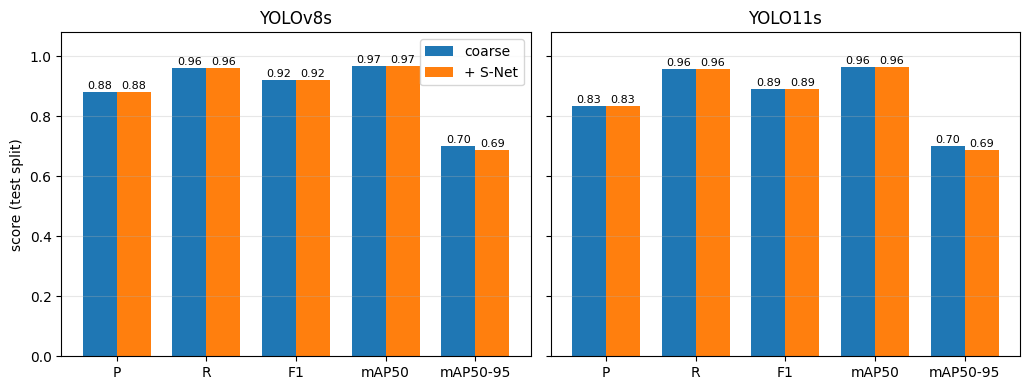

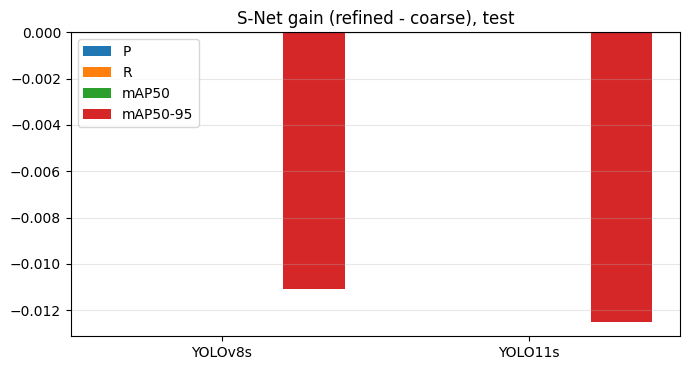

In [ ]:
MODELS = list(PRED.keys()); SPLIT_SHOW = "test"
metrics = ["P", "R", "F1", "mAP50", "mAP50-95"]
fig, axes = plt.subplots(1, len(MODELS), figsize=(5.2 * len(MODELS), 4), sharey=True, squeeze=False)
x = np.arange(len(metrics)); w = 0.38
for ax, m in zip(axes[0], MODELS):
    c = [RESULTS[(m, "coarse", SPLIT_SHOW)][k] for k in metrics]; r = [RESULTS[(m, "+S-Net", SPLIT_SHOW)][k] for k in metrics]
    b1 = ax.bar(x - w / 2, c, w, label="coarse"); b2 = ax.bar(x + w / 2, r, w, label="+ S-Net")
    for b in list(b1) + list(b2): ax.text(b.get_x() + b.get_width() / 2, b.get_height() + .01, f"{b.get_height():.2f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_title(m); ax.set_ylim(0, 1.08); ax.grid(axis="y", alpha=.3)
axes[0][0].legend(); axes[0][0].set_ylabel(f"score ({SPLIT_SHOW} split)")
plt.tight_layout(); plt.show()

# S-Net gain per detector
fig, ax = plt.subplots(figsize=(7, 3.8)); w = 0.25
for i, k in enumerate(["P", "R", "mAP50", "mAP50-95"][:4]):
    g = [RESULTS[(m, "+S-Net", SPLIT_SHOW)][k] - RESULTS[(m, "coarse", SPLIT_SHOW)][k] for m in MODELS]
    ax.bar(np.arange(len(MODELS)) + (i - 1.5) * 0.2, g, 0.2, label=k)
ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS)
ax.set_title(f"S-Net gain (refined - coarse), {SPLIT_SHOW}"); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 11. Precision graphs for every model

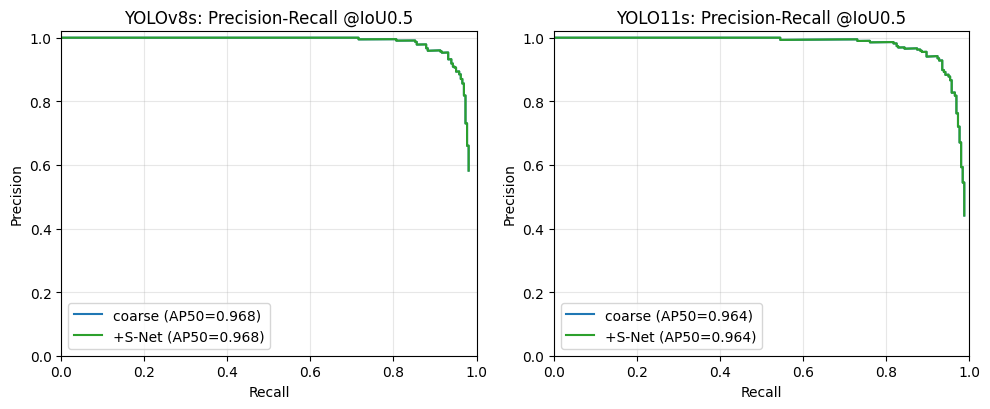

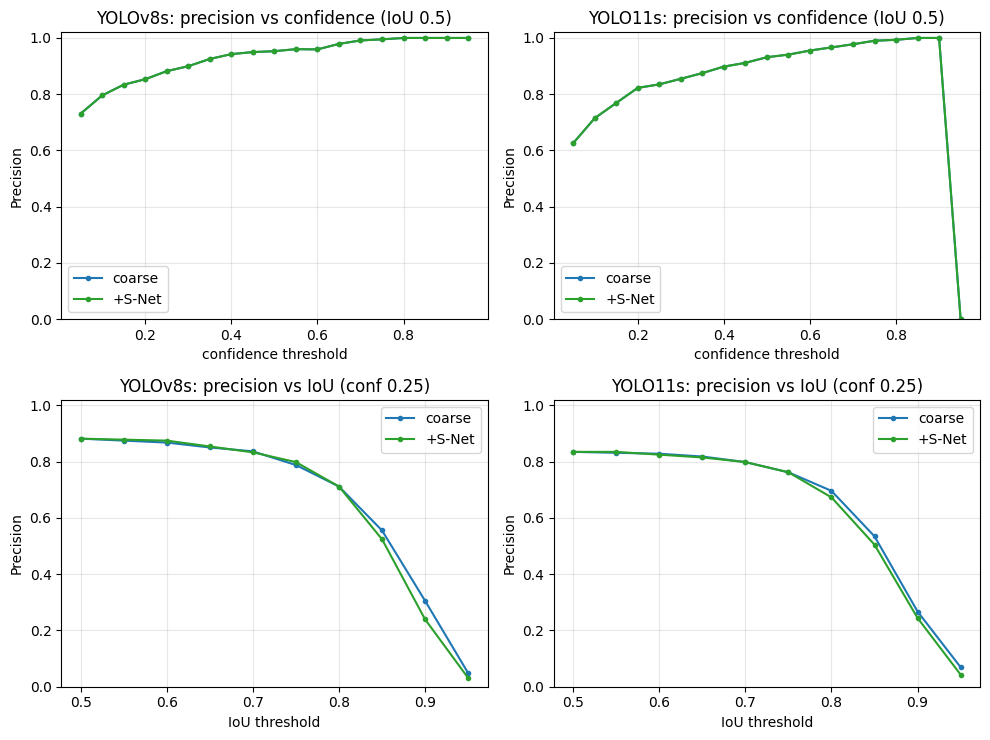

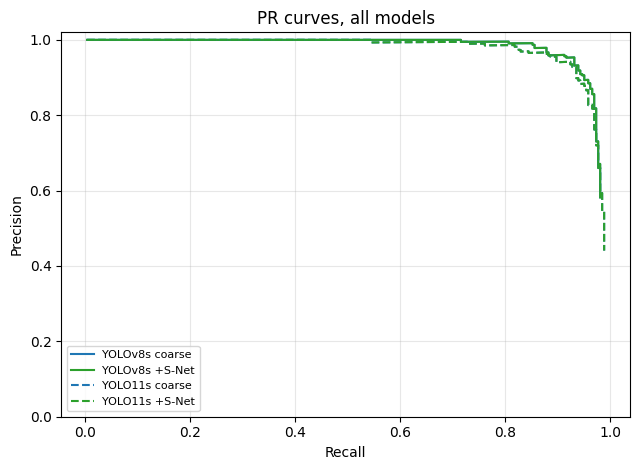

In [ ]:
COL = {"coarse": "tab:blue", "+S-Net": "tab:green"}

# (a) Precision-Recall curves at IoU 0.5
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.2), squeeze=False)
for ax, m in zip(axes[0], MODELS):
    for v in ("coarse", "+S-Net"):
        r = RESULTS[(m, v, SPLIT_SHOW)]; rec, prec = r["pr"]
        ax.plot(rec, prec, color=COL[v], label=f"{v} (AP50={r['mAP50']:.3f})")
    ax.set_title(f"{m}: Precision-Recall @IoU0.5"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

# (b) Precision vs confidence threshold, (c) precision vs IoU threshold
fig, axes = plt.subplots(2, len(MODELS), figsize=(5 * len(MODELS), 7.5), squeeze=False)
for j, m in enumerate(MODELS):
    for v in ("coarse", "+S-Net"):
        r = RESULTS[(m, v, SPLIT_SHOW)]
        axes[0][j].plot(CONF_GRID, r["p_conf"], color=COL[v], marker="o", ms=3, label=v)
        axes[1][j].plot(IOU_GRID, r["p_iou"], color=COL[v], marker="o", ms=3, label=v)
    axes[0][j].set_title(f"{m}: precision vs confidence (IoU 0.5)"); axes[0][j].set_xlabel("confidence threshold")
    axes[1][j].set_title(f"{m}: precision vs IoU (conf {OP_CONF})"); axes[1][j].set_xlabel("IoU threshold")
    for a in axes[:, j]: a.set_ylabel("Precision"); a.set_ylim(0, 1.02); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

# (d) all models on one PR plot
plt.figure(figsize=(6.5, 4.8))
for m, ls in zip(MODELS, ["-", "--", ":"]):
    for v in ("coarse", "+S-Net"):
        rec, prec = RESULTS[(m, v, SPLIT_SHOW)]["pr"]; plt.plot(rec, prec, ls, color=COL[v], label=f"{m} {v}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("PR curves, all models"); plt.grid(alpha=.3); plt.legend(fontsize=8); plt.ylim(0, 1.02)
plt.tight_layout(); plt.show()

## 12. Confusion matrices
Ship detection is single-class, so the matrix is *ship vs background* at `IOU_MATCH` and `OP_CONF`:
TP = matched detection, FP = detection with no ship, FN = missed ship. Background/background is undefined and left at 0.

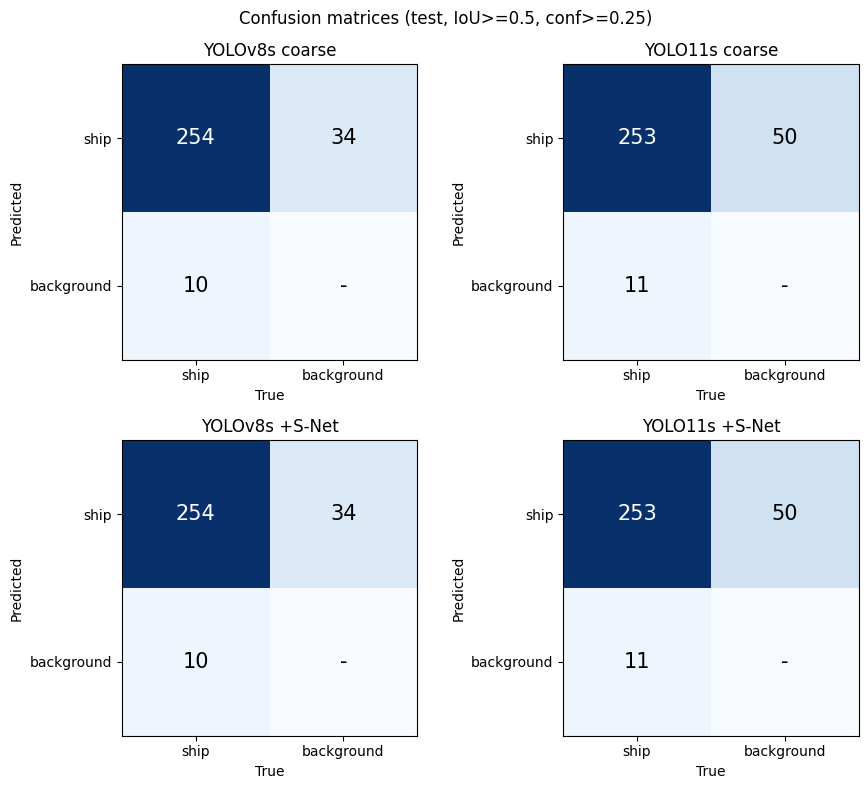

In [ ]:
fig, axes = plt.subplots(2, len(MODELS), figsize=(4.6 * len(MODELS), 8), squeeze=False)
for i, v in enumerate(("coarse", "+S-Net")):
    for j, m in enumerate(MODELS):
        cm = RESULTS[(m, v, SPLIT_SHOW)]["cm"]; ax = axes[i][j]
        ax.imshow(cm, cmap="Blues")
        for (a, b), val in np.ndenumerate(cm):
            ax.text(b, a, "-" if (a, b) == (1, 1) else str(val), ha="center", va="center", fontsize=15,
                    color="white" if val > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["ship", "background"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["ship", "background"])
        ax.set_xlabel("True"); ax.set_ylabel("Predicted"); ax.set_title(f"{m} {v}")
plt.suptitle(f"Confusion matrices ({SPLIT_SHOW}, IoU>={IOU_MATCH}, conf>={OP_CONF})"); plt.tight_layout(); plt.show()

## 13. Visual comparison on random test images

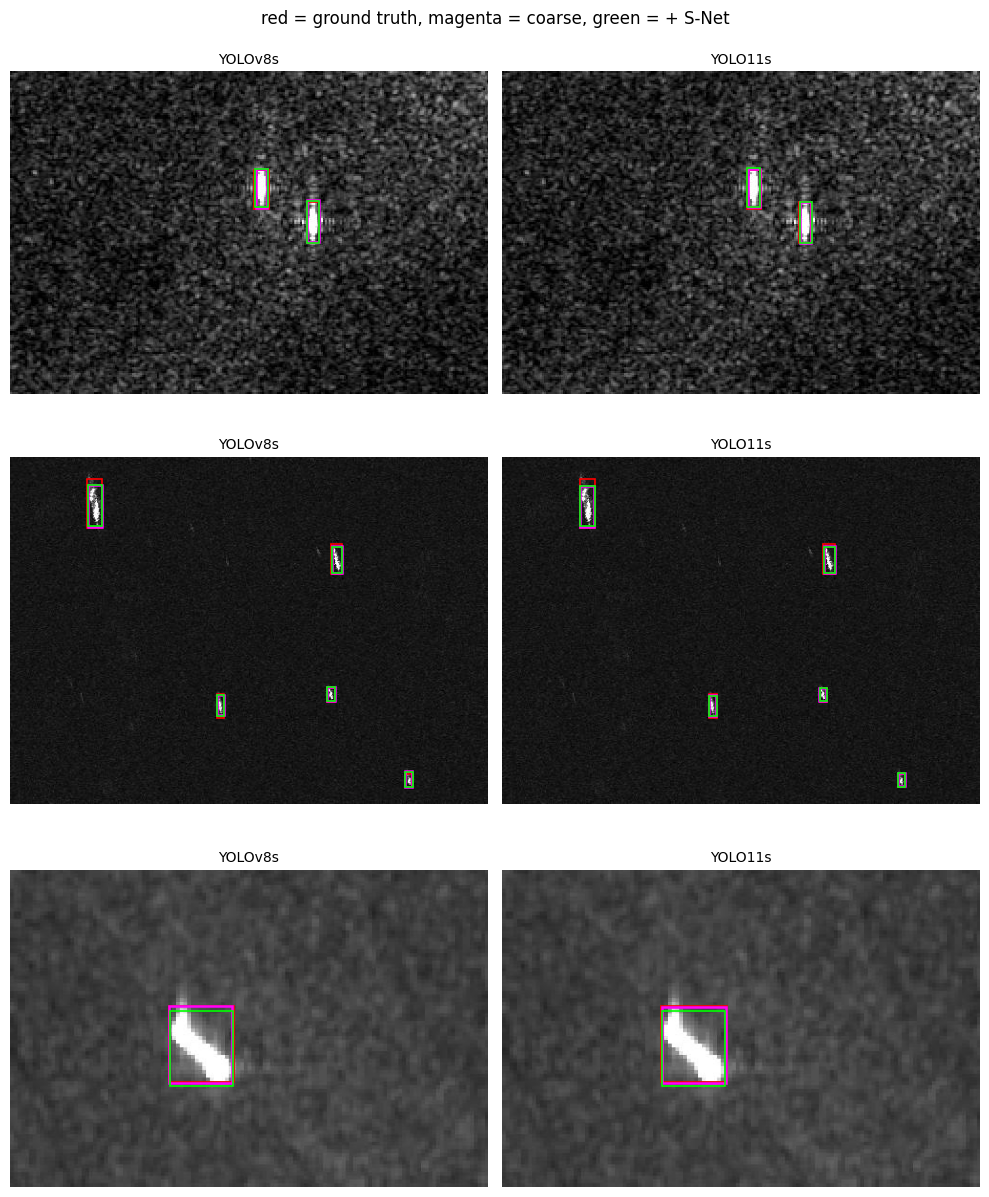

In [ ]:
def add_box(ax, b, color, lw=2): ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], lw=lw, ec=color, fc="none"))

names = random.SystemRandom().sample(IMGS["test"], 3)
fig, axes = plt.subplots(len(names), len(MODELS), figsize=(5 * len(MODELS), 4.2 * len(names)), squeeze=False)
for i, n in enumerate(names):
    for j, m in enumerate(MODELS):
        ax = axes[i][j]; ax.imshow(load_img("test", n)); ax.axis("off")
        for g in GT["test"][n]: add_box(ax, g, "red", 1.2)
        for var, col in (("coarse", "#FF00FF"), ("+S-Net", "#00FF00")):
            b, s = PRED[m][var]["test"][n]
            for bb in b[s >= OP_CONF]: add_box(ax, bb, col, 1.8 if var == "coarse" else 1.2)
        ax.set_title(f"{m}", fontsize=10)
fig.suptitle("red = ground truth, magenta = coarse, green = + S-Net"); plt.tight_layout(); plt.show()

## 14. Ship longitude / latitude and distance to the nearest dock

**Important:** SSDD images are cropped chips with **no geo-reference** (no corner coordinates, no pixel spacing in the files).
Real coordinates need, for each image, the scene centre (lat, lon) and the pixel size in metres. Two ways to supply them:

1. Put a `georef.csv` next to the notebook with columns `image,center_lat,center_lon,m_per_px` (one row per image), or
2. otherwise the **defaults below are used for every image**. Those defaults are placeholders, so the output is a demonstration
   of the method and **not real ship positions** until you replace them.

The conversion assumes a north-up image and a local flat-earth approximation (fine over a few km). Fill `DOCKS` with the real dock / quay coordinates of your harbour.

In [ ]:
DEFAULT_CENTER = (37.5500, 121.3900)   # PLACEHOLDER scene centre (lat, lon): replace
DEFAULT_M_PER_PX = 10.0                 # PLACEHOLDER pixel size in metres (SSDD is roughly 1-15 m): replace
DOCKS = {                               # PLACEHOLDER dock positions (lat, lon): replace with real ones
    "Dock A": (37.5560, 121.3850),
    "Dock B": (37.5440, 121.4000),
}
GEOREF_CSV = "georef.csv"
GEO = {}
if os.path.exists(GEOREF_CSV):
    g = pd.read_csv(GEOREF_CSV); GEO = {r.image: (r.center_lat, r.center_lon, r.m_per_px) for r in g.itertuples()}
    print("georef rows:", len(GEO))
else:
    print("No georef.csv -> using placeholder centre / resolution for every image")

M_PER_DEG_LAT = 111_320.0
def pixel_to_latlon(cx, cy, W, H, lat0, lon0, mpp):
    east = (cx - W / 2) * mpp; south = (cy - H / 2) * mpp
    return lat0 - south / M_PER_DEG_LAT, lon0 + east / (M_PER_DEG_LAT * math.cos(math.radians(lat0)))

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0088; p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))

def locate_ships(split, preds, conf=OP_CONF):
    recs = []
    for name, (boxes, scores) in preds.items():
        W, H = load_img(split, name).size
        stem = name
        lat0, lon0, mpp = GEO.get(stem, (*DEFAULT_CENTER, DEFAULT_M_PER_PX))
        k = 0
        for b, s in zip(boxes, scores):
            if s < conf: continue
            cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
            lat, lon = pixel_to_latlon(cx, cy, W, H, lat0, lon0, mpp)
            d = {dn: haversine_km(lat, lon, *dc) for dn, dc in DOCKS.items()}
            nd = min(d, key=d.get)
            k += 1
            recs.append(dict(image=name, ship=k, conf=round(float(s), 3), x_px=round(float(cx), 1), y_px=round(float(cy), 1),
                             length_m=round(float(max(b[2] - b[0], b[3] - b[1]) * mpp), 1),
                             latitude=round(lat, 6), longitude=round(lon, 6), nearest_dock=nd, dist_to_dock_km=round(d[nd], 3)))
    return pd.DataFrame(recs)

# use the best model on the test split (highest refined mAP50-95)
BEST = max(MODELS, key=lambda m: RESULTS[(m, "+S-Net", "test")]["mAP50-95"])
print("Best model:", BEST)
ships = locate_ships("test", PRED[BEST]["+S-Net"]["test"])
ships.to_csv("detected_ships_geo.csv", index=False)
print(len(ships), "ships detected in", ships.image.nunique(), "test images")
display(ships.head(15))

No georef.csv -> using placeholder centre / resolution for every image
Best model: YOLOv8s
288 ships detected in 116 test images


,image,ship,conf,x_px,y_px,length_m,latitude,longitude,nearest_dock,dist_to_dock_km
0,000014.jpg,1,0.820,134.0,158.2,1526.2,37.549713,121.382072,Dock A,0.745
1,000014.jpg,2,0.270,132.1,152.9,1554.6,37.550186,121.381851,Dock A,0.703
2,000024.jpg,1,0.606,267.7,143.5,1626.2,37.549911,121.397217,Dock B,0.702
3,000052.jpg,1,0.867,172.1,141.1,809.6,37.550259,121.390297,Dock A,0.791
4,000055.jpg,1,0.797,207.2,145.9,1286.8,37.551987,121.388657,Dock A,0.550
5,000062.jpg,1,0.857,210.9,181.5,994.1,37.548695,121.390266,Dock A,0.936
6,000066.jpg,1,0.900,170.1,148.6,889.2,37.551876,121.387680,Dock A,0.516
7,000089.jpg,1,0.850,131.1,73.7,201.8,37.556000,121.385124,Dock A,0.011
8,000089.jpg,2,0.846,293.5,171.1,253.6,37.547249,121.403542,Dock B,0.477
9,000089.jpg,3,0.826,266.2,84.1,258.4,37.555061,121.400452,Dock B,1.231


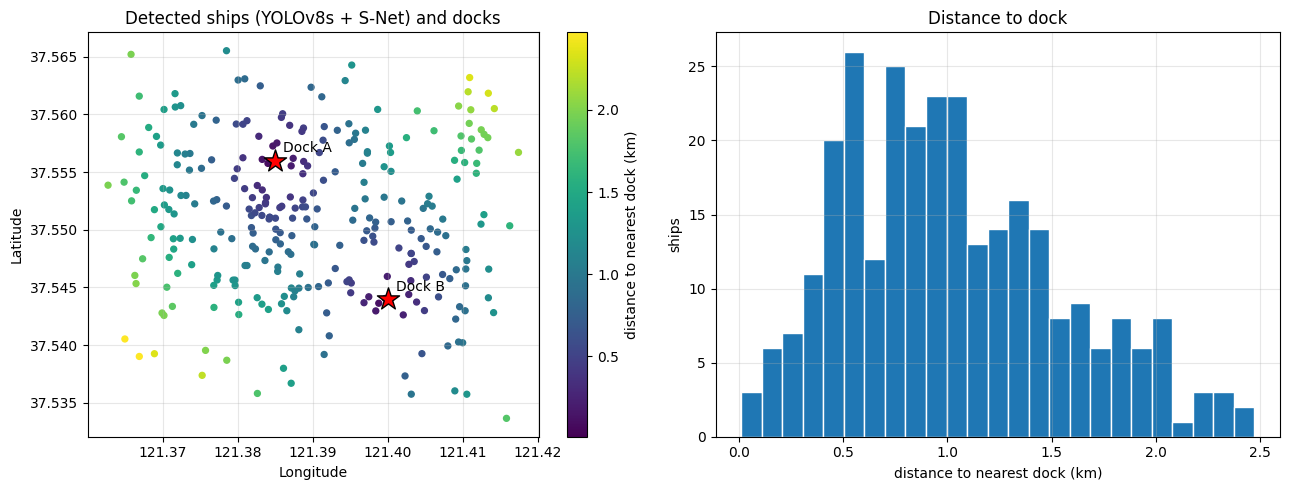

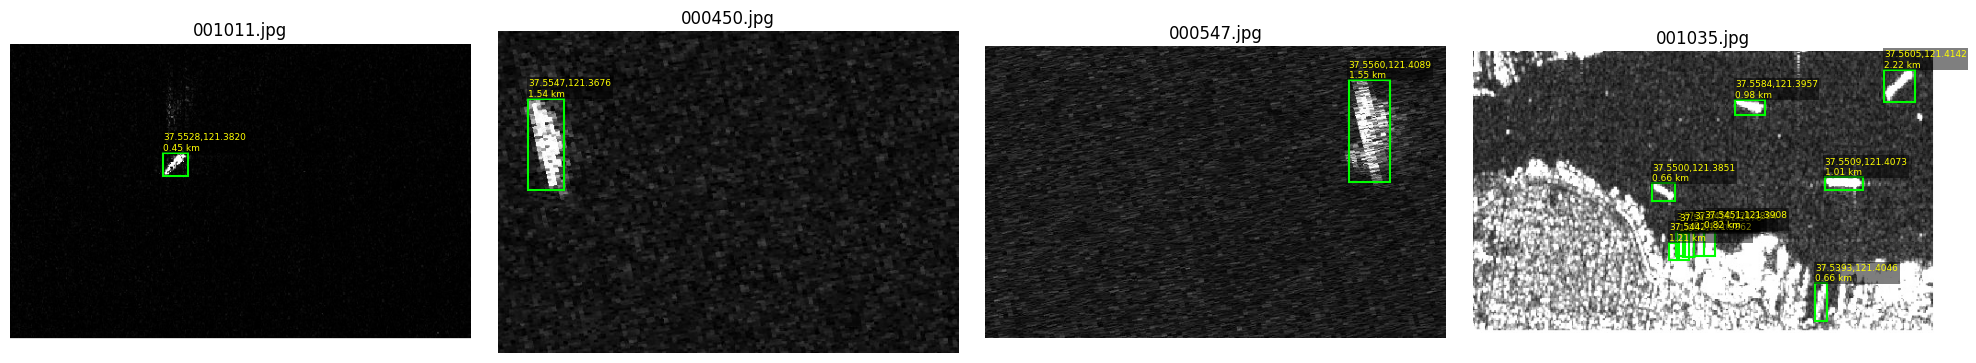

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sc = ax[0].scatter(ships.longitude, ships.latitude, c=ships.dist_to_dock_km, cmap="viridis", s=18)
plt.colorbar(sc, ax=ax[0], label="distance to nearest dock (km)")
for dn, (la, lo) in DOCKS.items():
    ax[0].scatter(lo, la, marker="*", s=280, c="red", edgecolors="k", zorder=5); ax[0].annotate(dn, (lo, la), xytext=(6, 6), textcoords="offset points")
ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude"); ax[0].set_title(f"Detected ships ({BEST} + S-Net) and docks"); ax[0].grid(alpha=.3)
ax[1].hist(ships.dist_to_dock_km, bins=25, color="tab:blue", edgecolor="w")
ax[1].set_xlabel("distance to nearest dock (km)"); ax[1].set_ylabel("ships"); ax[1].set_title("Distance to dock"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

# annotated example images
ex = ships.image.drop_duplicates().sample(min(4, ships.image.nunique()), random_state=1).tolist()
fig, axes = plt.subplots(1, len(ex), figsize=(5 * len(ex), 5), squeeze=False)
for a, n in zip(axes[0], ex):
    a.imshow(load_img("test", n)); a.axis("off"); a.set_title(n[:14])
    for r in ships[ships.image == n].itertuples():
        b, s = PRED[BEST]["+S-Net"]["test"][n]
        bb = b[np.argmin(np.abs((b[:, 0] + b[:, 2]) / 2 - r.x_px) + np.abs((b[:, 1] + b[:, 3]) / 2 - r.y_px))]
        add_box(a, bb, "#00FF00", 1.5)
        a.text(bb[0], bb[1] - 3, f"{r.latitude:.4f},{r.longitude:.4f}\n{r.dist_to_dock_km:.2f} km", color="yellow", fontsize=6.5,
               bbox=dict(fc="black", alpha=.5, pad=1, lw=0))
plt.tight_layout(); plt.show()

## 15. Save everything

In [ ]:
yolov8.save("YOLOv8s_SSDD.pt") if hasattr(yolov8, "save") else None
print("Files: results_summary.csv, snet_delta.csv, detected_ships_geo.csv, SNet_ROI_Refiner.keras")

Files: results_summary.csv, snet_delta.csv, detected_ships_geo.csv, SNet_ROI_Refiner.keras


In [ ]:
from google.colab import files
import os

for f in ["results_summary.csv", "snet_delta.csv", "detected_ships_geo.csv", "latex_tables.zip"]:
    if os.path.exists(f):
        files.download(f)
    else:
        print("missing:", f)

missing: results_summary.csv
missing: snet_delta.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

missing: latex_tables.zip


In [ ]:
import pandas as pd

# Reconstruct df and delta from the active RESULTS dictionary
rows = [dict(Model=m, Variant=v, Split=sp, **{k: r[k] for k in ("P", "R", "F1", "mAP50", "mAP50-95", "TP", "FP", "FN")})
        for (m, v, sp), r in RESULTS.items()]
df = pd.DataFrame(rows)

piv = df.pivot_table(index=["Model", "Split"], columns="Variant", values=["P", "R", "F1", "mAP50", "mAP50-95"])
delta = (piv.xs("+S-Net", axis=1, level=1) - piv.xs("coarse", axis=1, level=1)).round(4)

print("--- Test + Valid Metrics (results_summary) ---")
print(df.round(3).to_string(index=False))
print("\n--- S-Net Difference (snet_delta) ---")
print(delta.to_string())

--- Test + Valid Metrics (results_summary) ---
  Model Variant Split     P     R    F1  mAP50  mAP50-95  TP  FP  FN
YOLOv8s  coarse valid 0.886 0.925 0.905  0.958     0.699 210  27  17
YOLOv8s  +S-Net valid 0.890 0.930 0.909  0.959     0.686 211  26  16
YOLOv8s  coarse  test 0.882 0.962 0.920  0.968     0.700 254  34  10
YOLOv8s  +S-Net  test 0.882 0.962 0.920  0.968     0.689 254  34  10
YOLO11s  coarse valid 0.863 0.943 0.901  0.960     0.683 214  34  13
YOLO11s  +S-Net valid 0.859 0.938 0.897  0.959     0.680 213  35  14
YOLO11s  coarse  test 0.835 0.958 0.892  0.964     0.701 253  50  11
YOLO11s  +S-Net  test 0.835 0.958 0.892  0.964     0.689 253  50  11

--- S-Net Difference (snet_delta) ---
                   F1       P       R   mAP50  mAP50-95
Model   Split                                          
YOLO11s test   0.0000  0.0000  0.0000  0.0000   -0.0125
        valid -0.0042 -0.0040 -0.0044 -0.0017   -0.0030
YOLOv8s test   0.0000  0.0000  0.0000  0.0000   -0.0111
        valid

In [ ]:
import matplotlib.pyplot as plt
_n = [0]; _show = plt.show
def _save_show(*a, **k):
    _n[0] += 1; plt.savefig(f"fig_{_n[0]:02d}.png", dpi=200, bbox_inches="tight"); _show(*a, **k)
    plt.show = _save_show
    # now re-run the plotting cells of sections 10, 11, 12, 13 and 14, then:
    import glob; from google.colab import files
    [files.download(f) for f in sorted(glob.glob("fig_*.png"))]

In [ ]:
import numpy as np, random, matplotlib.pyplot as plt
MODELS = list(PRED.keys()); SPLIT_SHOW = "test"
COL = {"coarse": "tab:blue", "+S-Net": "tab:green"}
def save(name): plt.savefig(name, dpi=200, bbox_inches="tight"); plt.show()

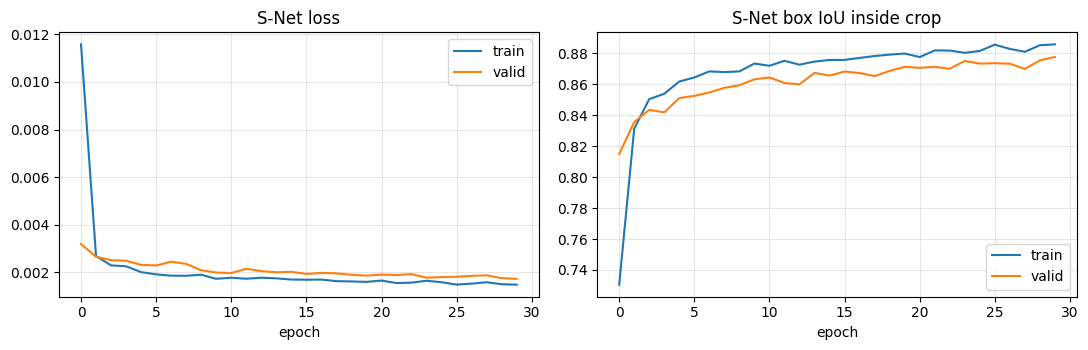

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="valid"); ax[0].set_title("S-Net loss")
ax[1].plot(hist.history["iou_metric"], label="train"); ax[1].plot(hist.history["val_iou_metric"], label="valid"); ax[1].set_title("S-Net box IoU inside crop")
for a in ax: a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); save("snet_training.png")
